# Personalized Artist Recommendation — Content-Based Filtering (CBF)

**How to run:** Upload the ZIP to Colab and choose `Runtime > Run all`. Results are saved to `/content/cbf_outputs`.

**Evaluation rules:** Settings are selected only on Dataset A validation. A-test and B validation/test are used only for the evaluation and diagnosis of the selected setting. No TF-IDF retraining on B. The official metrics are based on all held-out ground truth, and metrics based on ground truth inside the candidates are reported separately as supplementary. B is a **conditional external evaluation** on the common artist set built in preprocessing.
### Overall Processing Flow
`Load preprocessed ZIP → data validation → artist TF-IDF → user taste profile → cosine similarity Top-10 recommendation → A-validation model selection → A/B test evaluation → additional analyses → automatic checks and saving results`

**Core principle:** This implementation is based on the content-based filtering method presented in the team project proposal, and it builds the model and evaluates performance using the pre-processed datasets.

In [1]:
import os, io, json, zipfile, pathlib, hashlib, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import sparse
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.preprocessing import normalize
from IPython.display import display

SEED=42
np.random.seed(SEED)
TOPK=10
OUT=pathlib.Path('/content/cbf_outputs') if pathlib.Path('/content').exists() else pathlib.Path.cwd()/'cbf_outputs'
OUT.mkdir(parents=True,exist_ok=True)
print('결과 저장 위치:',OUT)

결과 저장 위치: /content/cbf_outputs


## 1. ZIP Upload and Loading Without Changing the Originals
**Key point:** The A/B data files made by the preprocessing teammate are read. The hash of the original ZIP is recorded so that the input used in a reproduction can be confirmed. If the Colab runtime is reset, the ZIP must be uploaded again.

In [2]:
from google.colab import files
uploaded=files.upload()
zip_names=[k for k in uploaded if k.lower().endswith('.zip')]
assert len(zip_names)==1, '전처리 ZIP 파일 하나만 업로드하세요.'
ZIP_BYTES=uploaded[zip_names[0]]
print('원본 ZIP SHA256:',hashlib.sha256(ZIP_BYTES).hexdigest())
with zipfile.ZipFile(io.BytesIO(ZIP_BYTES)) as z:
    names=set(z.namelist())
    required=['Lastfm.2k-a/artists.csv','Lastfm.2k-a/artist_tag_counts.csv',
      *[f'Lastfm.2k-a/{s}.csv' for s in ('train','validation','test')],
      'Lastfm.360k-b/content_candidate_artists.csv',
      *[f'Lastfm.360k-b/content_external_candidates/{s}.csv' for s in ('train','validation','test')]]
    assert set(required)<=names, f'필수 파일 누락: {set(required)-names}'
    data={f:pd.read_csv(z.open(f),low_memory=False) for f in required}
    report=json.load(z.open('report.json')) if 'report.json' in names else {}

a_art=data['Lastfm.2k-a/artists.csv'].copy()
tags=data['Lastfm.2k-a/artist_tag_counts.csv'].copy()
a={s:data[f'Lastfm.2k-a/{s}.csv'].copy() for s in ('train','validation','test')}
b_map=data['Lastfm.360k-b/content_candidate_artists.csv'].copy()
b={s:data[f'Lastfm.360k-b/content_external_candidates/{s}.csv'].copy() for s in ('train','validation','test')}
for label,parts in [('A',a),('B',b)]:
    for s,d in parts.items():print(label,s,d.shape,list(d.columns))
print('A catalog:',a_art.shape,'tag counts:',tags.shape,'B mapping:',b_map.shape)

Saving 전처리데이터.zip to 전처리데이터.zip
원본 ZIP SHA256: 9ef1b2df065009cc6e3be0060835b06ac171f42cefe267f9d6178d3f0ffff8ae
A train (55721, 6) ['user_index', 'artist_index', 'user_id', 'artist_id', 'plays', 'log1p_plays']
A validation (18540, 6) ['user_index', 'artist_index', 'user_id', 'artist_id', 'plays', 'log1p_plays']
A test (18540, 6) ['user_index', 'artist_index', 'user_id', 'artist_id', 'plays', 'log1p_plays']
B train (214507, 6) ['user_index', 'artist_index', 'user_id', 'artist_id', 'plays', 'log1p_plays']
B validation (64966, 6) ['user_index', 'artist_index', 'user_id', 'artist_id', 'plays', 'log1p_plays']
B test (64966, 6) ['user_index', 'artist_index', 'user_id', 'artist_id', 'plays', 'log1p_plays']
A catalog: (17632, 7) tag counts: (108433, 3) B mapping: (17632, 3)


## 2. Schema, ID, Split, and Leakage Validation

The data is not modified here. `artist_index` of different datasets is not used for joins. We check whether B's `artist_id` is linked to A's `artist_id`.
**Purpose of the validation:** We check the required columns, the validity of IDs and weights, and identical `(user_id, artist_id)` duplicates across train, validation, and test. Passing here, however, does not prove that there is no possible leakage in the raw preprocessing source data.

In [3]:
def require_columns(df,cols,name):
    missing=set(cols)-set(df.columns)
    assert not missing,f'{name} 컬럼 누락: {missing}'

require_columns(a_art,['artist_id','artist_index','name','content_eligible','distinct_tags'],'A artists')
require_columns(tags,['artist_id','tag','distinct_user_count'],'tags')
require_columns(b_map,['artist_index','a_artist_id','recommendation_candidate'],'B map')
assert a_art.artist_id.is_unique and a_art.artist_index.is_unique
assert b_map.artist_index.is_unique and b_map.a_artist_id.is_unique
assert set(b_map.a_artist_id)==set(a_art.artist_id)
assert a_art.content_eligible.isin([0,1]).all()
assert (a_art.loc[a_art.content_eligible.eq(1),'distinct_tags']>=2).all()
assert tags.artist_id.isin(a_art.artist_id).all()
assert tags[['artist_id','tag']].notna().all().all()
assert (tags.distinct_user_count>0).all()
assert not tags.duplicated(['artist_id','tag']).any()
assert (b_map.recommendation_candidate.isin([0,1])).all()
assert set(b_map.loc[b_map.recommendation_candidate.eq(1),'a_artist_id']).issubset(set(a_art.loc[a_art.content_eligible.eq(1),'artist_id']))

A_IDS=set(a_art.artist_id)
B_ALLOWED=set(b_map.a_artist_id)
def audit_splits(parts,label):
    sets=[]
    for split,df in parts.items():
        require_columns(df,['user_id','artist_id','plays','log1p_plays','artist_index','user_index'],f'{label} {split}')
        assert df[['user_id','artist_id','plays','log1p_plays']].notna().all().all()
        assert (df.plays>0).all()
        assert np.allclose(np.log1p(df.plays.to_numpy()),df.log1p_plays.to_numpy(),atol=1e-8)
        assert not df.duplicated(['user_id','artist_id']).any(),f'{label} {split}: 중복 interaction'
        assert set(df.artist_id)<=A_IDS,f'{label} {split}: A ID 연결 오류'
        assert df.groupby('user_id').user_index.nunique().max()==1
        assert df.groupby('artist_id').artist_index.nunique().max()==1
        sets.append(pd.MultiIndex.from_frame(df[['user_id','artist_id']]))
    for i in range(3):
        for j in range(i+1,3):
            assert len(sets[i].intersection(sets[j]))==0,f'{label}: {list(parts)[i]}/{list(parts)[j]} 누수'
    for split,df in parts.items():
        assert set(df.user_id)==set(parts['train'].user_id),f'{label}: 사용자 집합 불일치'
    print(label,'분할 중복 없음, ID/가중치 검증 통과')
audit_splits(a,'A');audit_splits(b,'B')
# B indices are not assumed to equal A’s: B data is joined only by artist_id.
assert b_map.a_artist_id.isin(a_art.artist_id).all()
print('B 추천 후보:',int(b_map.recommendation_candidate.sum()))

A 분할 중복 없음, ID/가중치 검증 통과
B 분할 중복 없음, ID/가중치 검증 통과
B 추천 후보: 9282


## 3. TF-IDF Artist Vectors

The `distinct_user_count` of the provided tags is used as TF. The default policy of the preprocessing report is **raw distinct-tagger TF × smoothed IDF, L2 normalization, eligible artists as documents**. The default policy is included in the experiment, and the comparison candidates are selected only on A-validation. The per-artist tag aggregation is static content metadata allowed by the proposal.
**Principle:** TF is the number of distinct users who assigned a given tag to the artist, and IDF is a factor that reduces the influence of tags common to many artists. After the TF-IDF transform, L2 normalization gives the artist vectors. The matrix size of this run is **10,425 artists × 9,583 tags**.

- **Raw TF:** reflects the number of users per tag
- **Binary TF:** reflects only whether the tag is present

In [4]:
# [Description] Build the TF-IDF matrix from the recommendable artists and their tags. The execution logic is identical to the original.
eligible=a_art.loc[a_art.content_eligible.eq(1),'artist_id'].tolist()
assert len(eligible)>0
artist_to_row={v:i for i,v in enumerate(eligible)}
used_tags=tags[tags.artist_id.isin(artist_to_row)].copy()
terms=sorted(used_tags.tag.unique().tolist())
term_to_col={t:i for i,t in enumerate(terms)}
rows=used_tags.artist_id.map(artist_to_row).to_numpy()
cols=used_tags.tag.map(term_to_col).to_numpy()
vals=used_tags.distinct_user_count.to_numpy(dtype=np.float64)
TF=sparse.csr_matrix((vals,(rows,cols)),shape=(len(eligible),len(terms)))
assert (np.diff(TF.indptr)>=2).all(),'eligible artist에 태그 2개 미만 존재'
print('TF matrix:',TF.shape,'nonzero:',TF.nnz)

def make_artist_vectors(tf_mode='raw',sublinear_tf=False):
    if tf_mode=='raw': X=TF.copy()
    elif tf_mode=='binary':
        X=TF.copy(); X.data=np.ones_like(X.data)
    else:raise ValueError(tf_mode)
    trans=TfidfTransformer(norm='l2',use_idf=True,smooth_idf=True,sublinear_tf=sublinear_tf)
    return trans.fit_transform(X).tocsr()

TF matrix: (10425, 9583) nonzero: 106725


## 4. User Profile and Top-10 Recommendation Functions

Only artists not yet listened to are recommended. The ground-truth split is not included in building user profiles. Users whose profile cannot be built are recorded explicitly and included with a score of 0 in the official all-user average.
**Profile principle:** The TF-IDF vectors of the artists the user listened to are summed with weights and normalized. `uniform` gives the same weight to every artist, and `log` reflects the log-transformed listening amount.

**Recommendation principle:** The dot product of the normalized user profile and the artist vector is the cosine similarity. Artists already heard are excluded, and the top **10** by score are recommended. The held-out ground truth is not put into the profile.

In [5]:
# [Description] Build profiles from users’ listening histories and recommend the Top-10 by cosine similarity.
def build_profiles(history,V,weight_mode):
    users=sorted(history.user_id.unique().tolist())
    uidx={u:i for i,u in enumerate(users)}
    h=history[history.artist_id.isin(artist_to_row)].copy()
    if weight_mode=='uniform':w=np.ones(len(h))
    elif weight_mode=='log':w=h.log1p_plays.to_numpy(dtype=float)
    else:raise ValueError(weight_mode)
    mat=sparse.csr_matrix((w,(h.user_id.map(uidx).to_numpy(),h.artist_id.map(artist_to_row).to_numpy())),shape=(len(users),len(eligible)))
    prof=normalize(mat@V,norm='l2',axis=1).tocsr()
    valid=np.asarray(prof.getnnz(axis=1)>0)
    return users,prof,valid

def recommend(history,V,weight_mode,candidate_ids,topk=10,batch_size=128):
    users,profiles,valid=build_profiles(history,V,weight_mode)
    candidate_ids=[i for i in candidate_ids if i in artist_to_row]
    assert len(candidate_ids)>0
    candidate_rows=np.array([artist_to_row[i] for i in candidate_ids])
    CV=V[candidate_rows]
    cand_pos={artist:i for i,artist in enumerate(candidate_ids)}
    listened=history.groupby('user_id').artist_id.agg(set).to_dict()
    records=[]
    for start in range(0,len(users),batch_size):
        end=min(start+batch_size,len(users))
        scores=(profiles[start:end]@CV.T).toarray()
        for j,user in enumerate(users[start:end]):
            if not valid[start+j]:continue
            seen=[cand_pos[x] for x in listened[user] if x in cand_pos]
            scores[j,seen]=-np.inf
            finite=np.isfinite(scores[j]); count=min(topk,int(finite.sum()))
            if count==0:continue
            # stable ties: ascending candidate_ids first
            inds=np.argpartition(-scores[j],count-1)[:count]
            inds=sorted(inds,key=lambda k:(-scores[j,k],candidate_ids[k]))
            for rank,k in enumerate(inds,1):
                records.append((user,candidate_ids[k],float(scores[j,k]),rank))
    result=pd.DataFrame(records,columns=['user_id','artist_id','score','rank'])
    assert not result.duplicated(['user_id','artist_id']).any()
    assert (result['rank']<=topk).all()
    assert not any(x in listened[u] for u,x in zip(result.user_id,result.artist_id))
    return result,pd.DataFrame({'user_id':users,'profile_available':valid})

## 5. Metric Definitions and Unit Tests

**Official evaluation:** Precision@10 = hits/10, Recall@10 = hits/number of all held-out ground truth, NDCG@10 = DCG/IDCG (based on all ground truth). The conditional Recall/NDCG based only on ground truth inside the candidate set are shown separately as **supplementary metrics**. The coverage denominator is the size of the recommendable catalog.
| Metric | Computation and meaning |
|---|---|
| Precision@10 | Number of hits ÷ 10; the hit ratio of the recommendation list |
| Recall@10 | Number of hits ÷ number of all hidden listened artists |
| NDCG@10 | Ranking metric that rewards placing hits higher |
| Catalog Coverage | Number of distinct artists recommended at least once ÷ number of all recommendation candidates |

**Example:** If 2 of 5 hidden ground-truth artists are hit with 10 recommendations, Precision = 0.2 and Recall = 0.4. Ground truth that is not among the candidates is also included in the denominator of the official Recall.

In [6]:
# [Description] Compute Precision/Recall/NDCG against all held-out ground truth and catalog coverage.
def evaluate(recs,truth,users,candidate_ids,k=10):
    users=list(users); truth_by=truth.groupby('user_id').artist_id.agg(set).to_dict()
    pred_by=recs.sort_values('rank').groupby('user_id').artist_id.agg(list).to_dict() if len(recs) else {}
    cand=set(candidate_ids); discount=1/np.log2(np.arange(2,k+2))
    records=[]
    for u in users:
        gt=truth_by.get(u,set()); pred=pred_by.get(u,[])
        assert len(gt)>0,f'{u}: 정답 없는 사용자'
        hit=np.array([int(x in gt) for x in pred[:k]],dtype=float)
        dcg=float((hit*discount[:len(hit)]).sum())
        reachable=gt&cand
        records.append({'user_id':u,'precision10':float(hit.sum()/k),
           'recall10':float(hit.sum()/len(gt)),
           'ndcg10':float(dcg/discount[:min(k,len(gt))].sum()),
           'conditional_recall10':float(hit.sum()/len(reachable)) if reachable else np.nan,
           'conditional_ndcg10':float(dcg/discount[:min(k,len(reachable))].sum()) if reachable else np.nan,
           'gt_count':len(gt),'reachable_gt':len(reachable),'hits':int(hit.sum()),'recommendations':len(pred)})
    per=pd.DataFrame(records)
    summary={c:float(per[c].mean()) for c in ['precision10','recall10','ndcg10','conditional_recall10','conditional_ndcg10']}
    summary.update({'catalog_coverage':float(recs.artist_id.nunique()/len(cand)),
       'reachable_gt_fraction':float(per.reachable_gt.sum()/per.gt_count.sum()),
       'users':len(users),'users_with_reachable_gt':int((per.reachable_gt>0).sum()),
       'recommended_users':int((per.recommendations>0).sum()),'catalog_size':len(cand)})
    return summary,per

# Small computation check: the case where 1 ground-truth item is hit at rank 1
_t=pd.DataFrame({'user_id':['u'],'artist_id':[101]})
_r=pd.DataFrame({'user_id':['u'],'artist_id':[101],'rank':[1],'score':[1.]})
_s,_=evaluate(_r,_t,['u'],[101,102],10)
assert np.isclose(_s['precision10'],0.1) and np.isclose(_s['recall10'],1.) and np.isclose(_s['ndcg10'],1.)
print('평가 지표 단위 테스트 통과')

평가 지표 단위 테스트 통과


## 6. Dataset A Validation: Comparing TF-IDF × Profile Weighting

Four experiments are fixed in advance: raw/binary TF × uniform/log profile. **Final selection criterion: maximum A-validation NDCG@10**, with ties broken by Recall@10, Precision@10, and name. A-test and B data take no part in this selection.
**Actual A-validation NDCG@10:** Raw+Uniform **0.103930**, Raw+Log 0.103774, Binary+Log 0.073528, Binary+Uniform 0.068967. **Raw+Uniform** was therefore chosen as the final setting. The difference from Raw+Log is small, about 0.000156, so it is not interpreted as a large performance gap.

In [7]:
# [Description] Select the final model setting using only A-validation NDCG@10.
A_CAND=sorted(eligible)
variants=[('raw','uniform'),('raw','log'),('binary','uniform'),('binary','log')]
vector_cache={tf:make_artist_vectors(tf) for tf in ['raw','binary']}
val_results=[]
for tf_mode,weight_mode in variants:
    rec,availability=recommend(a['train'],vector_cache[tf_mode],weight_mode,A_CAND)
    summ,per=evaluate(rec,a['validation'],sorted(a['train'].user_id.unique()),A_CAND)
    val_results.append({'tf_mode':tf_mode,'weight_mode':weight_mode,**summ})
    print(tf_mode,weight_mode,'NDCG@10',round(summ['ndcg10'],5),'Recall@10',round(summ['recall10'],5))
val_df=pd.DataFrame(val_results).sort_values(['ndcg10','recall10','precision10','tf_mode','weight_mode'],ascending=[False,False,False,True,True]).reset_index(drop=True)
display(val_df)
val_df.to_csv(OUT/'A_validation_model_selection.csv',index=False)
BEST_TF=str(val_df.iloc[0].tf_mode);BEST_WEIGHT=str(val_df.iloc[0].weight_mode)
V=vector_cache[BEST_TF]
print('확정 모델:',BEST_TF,BEST_WEIGHT)
(OUT/'selected_config.json').write_text(json.dumps({'tf_mode':BEST_TF,'weight_mode':BEST_WEIGHT,'selection':'Dataset A validation NDCG@10','seed':SEED},indent=2))

raw uniform NDCG@10 0.10393 Recall@10 0.09268
raw log NDCG@10 0.10377 Recall@10 0.09362
binary uniform NDCG@10 0.06897 Recall@10 0.06473
binary log NDCG@10 0.07353 Recall@10 0.06851


,tf_mode,weight_mode,precision10,recall10,ndcg10,conditional_recall10,conditional_ndcg10,catalog_coverage,reachable_gt_fraction,users,users_with_reachable_gt,recommended_users,catalog_size
0,raw,uniform,0.091422,0.092678,0.103930,0.102412,0.110205,0.232230,0.90836,1877,1874,1877,10425
1,raw,log,0.092701,0.093618,0.103774,0.103465,0.110153,0.232806,0.90836,1877,1874,1877,10425
2,binary,log,0.067501,0.068513,0.073528,0.075568,0.078006,0.293909,0.90836,1877,1874,1877,10425
3,binary,uniform,0.063985,0.064730,0.068967,0.071798,0.073285,0.290456,0.90836,1877,1874,1877,10425


확정 모델: raw uniform


111

## 7. Final Internal Evaluation on A and External Evaluation on B

**Important:** For A-test, user profiles are built from the `A train + A validation` listening history and only A-test is used as the ground truth. This uses the history observable up to just before test, after the model setting was chosen on A-validation. External B is evaluated in the same way: `B train + B validation` for B-test. The separate diagnosis of B-validation itself is done with B-train only. All observed listened artists are excluded from the recommendation candidates during evaluation.
**Summary of final performance:**

| Metric | A-test | B-test |
|---|---:|---:|
| Number of users | 1,877 | 9,931 |
| Precision@10 | 0.097283 | 0.055422 |
| Recall@10 | 0.099183 | 0.087808 |
| NDCG@10 | **0.113545** | **0.083118** |
| Catalog Coverage | 22.96% | 40.11% |

B uses the TF-IDF representation learned on A **without retraining**. The users and candidate sets of the two datasets differ, so the score difference cannot be read directly as a ranking of model performance.

In [8]:
# [Description] In the final test evaluation, test listening records are not put into user profiles.
a_hist=pd.concat([a['train'],a['validation']],ignore_index=True)
b_hist=pd.concat([b['train'],b['validation']],ignore_index=True)
B_CAND=sorted(b_map.loc[b_map.recommendation_candidate.eq(1),'a_artist_id'].tolist())
assert set(B_CAND)<=set(A_CAND)
# B external profiles use A’s representation as is (no TF-IDF retraining)
a_rec,a_available=recommend(a_hist,V,BEST_WEIGHT,A_CAND)
b_val_rec,b_val_available=recommend(b['train'],V,BEST_WEIGHT,B_CAND)
b_rec,b_available=recommend(b_hist,V,BEST_WEIGHT,B_CAND)
A_SUM,A_PER=evaluate(a_rec,a['test'],sorted(a_hist.user_id.unique()),A_CAND)
BV_SUM,BV_PER=evaluate(b_val_rec,b['validation'],sorted(b['train'].user_id.unique()),B_CAND)
B_SUM,B_PER=evaluate(b_rec,b['test'],sorted(b_hist.user_id.unique()),B_CAND)
summary=pd.DataFrame([{'dataset':'A_test',**A_SUM},{'dataset':'B_validation_diagnostic',**BV_SUM},{'dataset':'B_test',**B_SUM}])
display(summary.T)
summary.to_csv(OUT/'evaluation_summary.csv',index=False)
for name,df in [('A_test_user_metrics',A_PER),('B_validation_user_metrics',BV_PER),('B_test_user_metrics',B_PER),('A_test_recommendations',a_rec),('B_test_recommendations',b_rec)]:
    df.to_csv(OUT/(name+'.csv'),index=False)

,0,1,2
dataset,A_test,B_validation_diagnostic,B_test
precision10,0.097283,0.052694,0.055422
recall10,0.099183,0.08277,0.087808
ndcg10,0.113545,0.077186,0.083118
conditional_recall10,0.108941,0.08277,0.087808
conditional_ndcg10,0.120233,0.077186,0.083118
catalog_coverage,0.22964,0.412088,0.401099
reachable_gt_fraction,0.909169,1.0,1.0
users,1877,9931,9931
users_with_reachable_gt,1875,9931,9931


## 8. External Evaluation: Matching Scope, Reachable Ground Truth, and Profile Feasibility

The external results of Dataset B are limited to the common-artist evaluation targets defined in the preprocessing ZIP. The **match rate over the whole raw B** can be reported only when the preprocessing report provides such a figure, and the figure of the current candidate split is not called the match rate over the whole raw data.
**Evaluation scope:** B's recommendation candidates are **9,282** artists that were reliably linked in preprocessing. The 52.64% against the 17,632 entries of the preprocessing mapping list is *not the match rate over all raw B artists*. B's reachable ground-truth fraction of 100% is also a figure within this restricted evaluation set. For A it is about 90.92%.

In [9]:
reach=pd.DataFrame([{'dataset':'A_test','eligible_catalog':len(A_CAND),'users':A_SUM['users'],'reachable_gt_fraction':A_SUM['reachable_gt_fraction'],'users_without_reachable_gt':int((A_PER.reachable_gt==0).sum()),'users_without_profile':int((~a_available.profile_available).sum())},
 {'dataset':'B_test','eligible_catalog':len(B_CAND),'users':B_SUM['users'],'reachable_gt_fraction':B_SUM['reachable_gt_fraction'],'users_without_reachable_gt':int((B_PER.reachable_gt==0).sum()),'users_without_profile':int((~b_available.profile_available).sum())}])
display(reach);reach.to_csv(OUT/'eligibility_and_reachability.csv',index=False)
print('B 전처리 후보 매핑 수:',len(b_map),'추천 가능:',len(B_CAND),'비율:',round(len(B_CAND)/len(b_map),4))
print('주의: 위 비율은 원본 B 전체 아티스트 매칭률이 아닙니다.')

,dataset,eligible_catalog,users,reachable_gt_fraction,users_without_reachable_gt,users_without_profile
0,A_test,10425,1877,0.909169,2,0
1,B_test,9282,9931,1.000000,0,0


B 전처리 후보 매핑 수: 17632 추천 가능: 9282 비율: 0.5264
주의: 위 비율은 원본 B 전체 아티스트 매칭률이 아닙니다.


## 9. Popularity and Novelty

Popularity is computed as the number of users who listened to the artist in each dataset's **observed history for evaluation (train+validation)**. Test is not used to compute popularity. Novelty measures the degree to which relatively less well-known artists are recommended. It is defined as `-log2((listeners+1)/(number_of_users+1))` and is a smoothed, observation-based *proxy*. The user populations of A and B differ, so absolute comparisons must be made with care.
**Interpretation:** `listeners` is the number of distinct users who listened to the artist in the observed listening history. A higher novelty means an artist that is less popular in the observations. This is not a direct measurement of the novelty actual users feel.

,dataset,mean_listeners,median_listeners,mean_novelty,recommended_rows
0,A_test,63.982898,27.0,6.438507,18770
1,B_test,199.007713,85.0,7.272798,99310


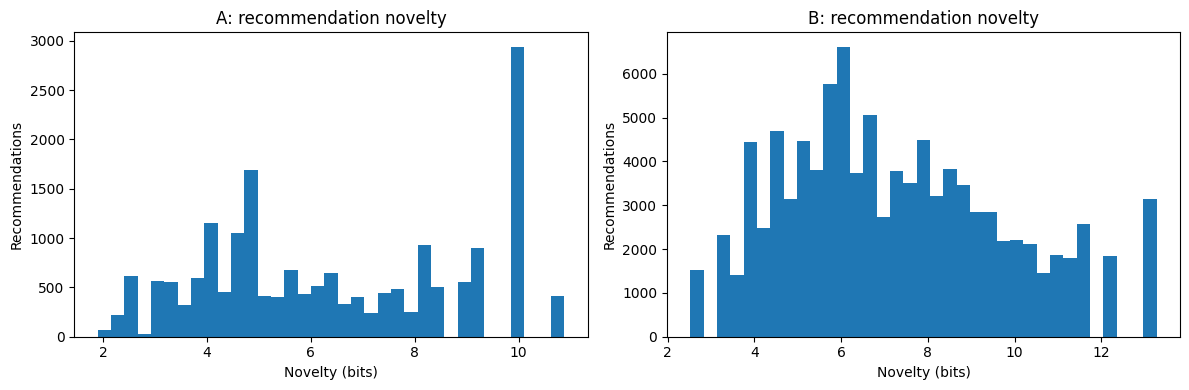

In [10]:
def popularity_analysis(history,recs,name):
    listeners=history.groupby('artist_id').user_id.nunique()
    N=history.user_id.nunique()
    out=recs.copy()
    out['listeners']=out.artist_id.map(listeners).fillna(0).astype(int)
    out['listener_fraction']=out.listeners/N
    out['novelty_bits']=-np.log2((out.listeners+1)/(N+1))
    out.to_csv(OUT/(name+'_popularity_novelty.csv'),index=False)
    return out,{'dataset':name,'mean_listeners':out.listeners.mean(),'median_listeners':out.listeners.median(),'mean_novelty':out.novelty_bits.mean(),'recommended_rows':len(out)}
A_POP,A_POP_SUM=popularity_analysis(a_hist,a_rec,'A_test')
B_POP,B_POP_SUM=popularity_analysis(b_hist,b_rec,'B_test')
display(pd.DataFrame([A_POP_SUM,B_POP_SUM]))
fig,axs=plt.subplots(1,2,figsize=(12,4))
for ax,d,name in zip(axs,[A_POP,B_POP],['A','B']):
    ax.hist(d.novelty_bits,bins=35);ax.set_title(f'{name}: recommendation novelty');ax.set_xlabel('Novelty (bits)');ax.set_ylabel('Recommendations')
plt.tight_layout();plt.savefig(OUT/'novelty_distribution.png',dpi=160);plt.show()

## 10. Distribution of Per-User Performance and Sparsity Analysis

We explore performance by the number of observed listened artists. Causation is not claimed from correlation alone.
**Analysis:** We look at the distribution of per-user Recall/NDCG and compare group means after splitting the number of observed listened artists into `1~5 / 6~15 / 16~30 / 31+`. Groups with small samples are not over-interpreted.

A_test


,history_group,users,mean_recall10,mean_ndcg10
0,1-5,1,0.000000,0.000000
1,6-15,16,0.177083,0.085162
2,16-30,16,0.158036,0.156702
3,31+,1844,0.098051,0.113478


B_test


,history_group,users,mean_recall10,mean_ndcg10
0,1-5,38,0.157895,0.073128
1,6-15,716,0.137803,0.091709
2,16-30,4775,0.082823,0.075990
3,31+,4402,0.084479,0.089540


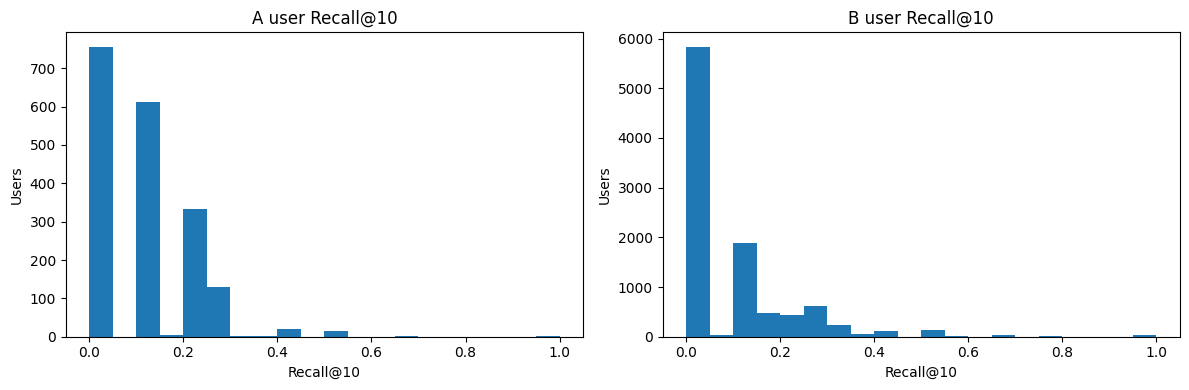

In [11]:
def user_analysis(per,history,name):
    counts=history.groupby('user_id').artist_id.nunique().rename('observed_artists')
    result=per.merge(counts,left_on='user_id',right_index=True,how='left',validate='one_to_one')
    result['history_group']=pd.cut(result.observed_artists,bins=[0,5,15,30,np.inf],labels=['1-5','6-15','16-30','31+'])
    table=result.groupby('history_group',observed=False).agg(users=('user_id','size'),mean_recall10=('recall10','mean'),mean_ndcg10=('ndcg10','mean')).reset_index()
    result.to_csv(OUT/(name+'_user_analysis.csv'),index=False)
    table.to_csv(OUT/(name+'_history_group_analysis.csv'),index=False)
    print(name);display(table)
    return result
A_USER=user_analysis(A_PER,a_hist,'A_test');B_USER=user_analysis(B_PER,b_hist,'B_test')
fig,axs=plt.subplots(1,2,figsize=(12,4))
for ax,df,name in zip(axs,[A_USER,B_USER],['A','B']):
    ax.hist(df.recall10,bins=np.linspace(0,1,21));ax.set_title(name+' user Recall@10');ax.set_xlabel('Recall@10');ax.set_ylabel('Users')
plt.tight_layout();plt.savefig(OUT/'user_recall_distribution.png',dpi=160);plt.show()

## 11. Bootstrap 95% Confidence Intervals

Resampling with replacement at the user level estimates **the uncertainty of each dataset's mean performance**. Because A and B have different evaluation sets, whether the confidence intervals overlap is not used alone to judge significance between the two datasets.
**Method:** The per-user performance is resampled **2,000 times**, and the 2.5% and 97.5% percentiles of the mean give the confidence interval. The random seed is fixed to improve reproducibility on reruns. This is uncertainty from the user sample and does not account for all data biases.

In [12]:
def bootstrap_ci(per,metric,n_boot=2000,seed=SEED):
    x=per[metric].dropna().to_numpy(dtype=float)
    if len(x)==0:return (np.nan,np.nan)
    rng=np.random.default_rng(seed)
    means=np.empty(n_boot)
    for i in range(n_boot):means[i]=x[rng.integers(0,len(x),size=len(x))].mean()
    return tuple(np.quantile(means,[.025,.975]))
ci=[]
for name,per in [('A_test',A_PER),('B_test',B_PER)]:
    for metric in ['precision10','recall10','ndcg10']:
        lo,hi=bootstrap_ci(per,metric)
        ci.append({'dataset':name,'metric':metric,'mean':per[metric].mean(),'ci_low':lo,'ci_high':hi})
ci_df=pd.DataFrame(ci);display(ci_df);ci_df.to_csv(OUT/'bootstrap_95ci.csv',index=False)

,dataset,metric,mean,ci_low,ci_high
0,A_test,precision10,0.097283,0.092595,0.101758
1,A_test,recall10,0.099183,0.094252,0.103975
2,A_test,ndcg10,0.113545,0.107761,0.119292
3,B_test,precision10,0.055422,0.053902,0.056963
4,B_test,recall10,0.087808,0.085116,0.090427
5,B_test,ndcg10,0.083118,0.080671,0.085632


## 12. Recommendation Evidence and Success and Failure Cases

The explanation computes the **per-tag dot-product contributions** of the actual score. The tag contributions are for explanation and do not modify the recommendation score. Success and failure are classified by whether the held-out ground truth was hit, and success is not used to readjust the model.
**Explanation principle:** The dot product of the user profile and the recommended artist vector is decomposed into per-tag contributions, and the main evidence for the recommendation is shown. `heldout_hit=True` means a hidden listening record was hit, and `False` does not mean the user dislikes the artist.

In [13]:
name_by_id=a_art.set_index('artist_id')['name'].to_dict()
def explain_user(user,history,recs,V,weight_mode,truth=None,n_recs=5,n_tags=5):
    sub=history.loc[history.user_id.eq(user)]
    users,profiles,valid=build_profiles(sub,V,weight_mode)
    if not len(users) or not valid[0]:return pd.DataFrame()
    p=profiles.getrow(0)
    rr=recs.loc[recs.user_id.eq(user)].sort_values('rank').head(n_recs)
    gt=set(truth.loc[truth.user_id.eq(user),'artist_id']) if truth is not None else set()
    records=[]
    for r in rr.itertuples():
        v=V.getrow(artist_to_row[r.artist_id]); contrib=p.multiply(v).tocoo()
        inds=np.argsort(-contrib.data)[:n_tags]
        explanation=', '.join(f'{terms[contrib.col[j]]} ({contrib.data[j]:.3f})' for j in inds)
        records.append({'user_id':user,'rank':r.rank,'artist_id':r.artist_id,'artist_name':name_by_id.get(r.artist_id,''),'cosine_score':r.score,'heldout_hit':r.artist_id in gt,'top_contributing_tags':explanation})
    return pd.DataFrame(records)

def examples(per,history,recs,truth,V,weight_mode,name):
    # Success: among users with hits, higher recall first; failure: among users with 0 hits, those who have recommendations
    good=per.loc[per.hits.gt(0)].sort_values(['recall10','ndcg10'],ascending=False).head(2).user_id.tolist()
    bad=per.loc[per.hits.eq(0)&per.recommendations.gt(0)].sort_values('gt_count',ascending=False).head(2).user_id.tolist()
    frames=[]
    for typ,ids in [('success',good),('failure',bad)]:
        for u in ids:
            e=explain_user(u,history,recs,V,weight_mode,truth,n_recs=10)
            if len(e):e.insert(0,'case_type',typ);frames.append(e)
    out=pd.concat(frames,ignore_index=True) if frames else pd.DataFrame()
    display(out.head(30));out.to_csv(OUT/(name+'_explained_examples.csv'),index=False)
    return out
A_EX=examples(A_PER,a_hist,a_rec,a['test'],V,BEST_WEIGHT,'A_test')
B_EX=examples(B_PER,b_hist,b_rec,b['test'],V,BEST_WEIGHT,'B_test')

,case_type,user_id,rank,artist_id,artist_name,cosine_score,heldout_hit,top_contributing_tags
0,success,1773,1,525,Gwen Stefani,0.835535,False,"pop (0.392), dance (0.213), female vocalists (..."
1,success,1773,2,67,Madonna,0.773640,False,"pop (0.269), dance (0.230), female vocalists (..."
2,success,1773,3,652,Hadise,0.770518,False,"dance (0.317), pop (0.300), female vocalists (..."
3,success,1773,4,14898,Honey,0.770518,False,"dance (0.317), pop (0.300), female vocalists (..."
4,success,1773,5,9232,beFour,0.747868,False,"dance (0.384), pop (0.364)"
5,success,1773,6,300,Katy Perry,0.740145,False,"pop (0.353), female vocalists (0.104), dance (..."
6,success,1773,7,466,Ke$ha,0.738340,False,"pop (0.284), dance (0.259), female vocalists (..."
7,success,1773,8,2521,Robyn,0.737629,False,"pop (0.265), dance (0.237), electronic (0.082)..."
8,success,1773,9,523,Lindsay Lohan,0.721526,True,"pop (0.316), dance (0.181), female vocalists (..."
9,success,1773,10,288,Rihanna,0.720450,True,"pop (0.253), dance (0.198), female vocalists (..."


,case_type,user_id,rank,artist_id,artist_name,cosine_score,heldout_hit,top_contributing_tags
0,success,21df03534d268960e08e3c2d9b1d6f24e1f67993,1,1705,Hans Zimmer,0.508051,True,"soundtrack (0.247), classical (0.128), instrum..."
1,success,21df03534d268960e08e3c2d9b1d6f24e1f67993,2,592,Ennio Morricone,0.498032,False,"soundtrack (0.207), classical (0.160), instrum..."
2,success,21df03534d268960e08e3c2d9b1d6f24e1f67993,3,2446,Howard Shore,0.489487,False,"soundtrack (0.236), classical (0.137), instrum..."
3,success,21df03534d268960e08e3c2d9b1d6f24e1f67993,4,8234,Kronos Quartet,0.482225,False,"classical (0.329), instrumental (0.082), sound..."
4,success,21df03534d268960e08e3c2d9b1d6f24e1f67993,5,979,Smash Mouth,0.473546,False,"rock (0.142), 90s (0.104), alternative rock (0..."
5,success,21df03534d268960e08e3c2d9b1d6f24e1f67993,6,910,John Williams,0.467533,False,"soundtrack (0.220), classical (0.155), instrum..."
6,success,21df03534d268960e08e3c2d9b1d6f24e1f67993,7,3464,Counting Crows,0.464167,False,"90s (0.112), rock (0.102), soundtrack (0.085),..."
7,success,21df03534d268960e08e3c2d9b1d6f24e1f67993,8,13910,Antonín Dvořák,0.451663,False,"classical (0.367), instrumental (0.023), roman..."
8,success,21df03534d268960e08e3c2d9b1d6f24e1f67993,9,12288,James Newton Howard,0.445905,False,"soundtrack (0.180), instrumental (0.104), clas..."
9,success,21df03534d268960e08e3c2d9b1d6f24e1f67993,10,14391,Giovanni Allevi,0.443023,False,"classical (0.322), instrumental (0.121)"


## 13. Final Automatic Checks and Result Visualization and Saving

Automatic checks are performed to confirm the correctness of the final recommendations and the performance evaluation. They check whether recommended artists are inside the candidate set, whether artists already listened to are excluded, duplicate recommendation ranks, the condition of at most 10 recommendations per user, duplicates between user profiles and the test ground-truth data, and the valid range of the evaluation metrics.

The final evaluation results of Dataset A and Dataset B are then visualized to check the recommendation performance on each dataset. However, the two datasets differ in user population and recommendation candidates, so the performance difference is not read as a direct ranking.

A 최종 자동 검증 통과
B 최종 자동 검증 통과


,dataset,precision10,recall10,ndcg10,catalog_coverage,reachable_gt_fraction
0,A_test,0.097283,0.099183,0.113545,0.229640,0.909169
2,B_test,0.055422,0.087808,0.083118,0.401099,1.000000


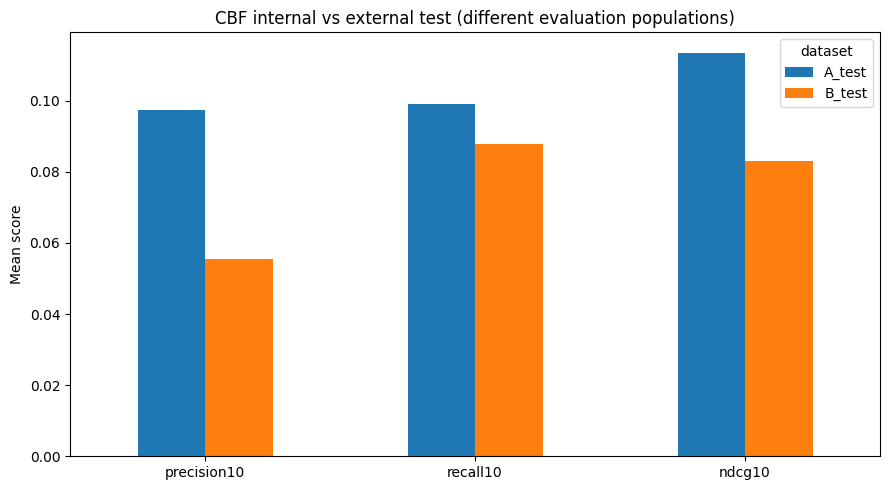

최종 산출물: ['A_B_performance.png', 'A_test_explained_examples.csv', 'A_test_history_group_analysis.csv', 'A_test_popularity_novelty.csv', 'A_test_recommendations.csv', 'A_test_user_analysis.csv', 'A_test_user_metrics.csv', 'A_validation_model_selection.csv', 'B_test_explained_examples.csv', 'B_test_history_group_analysis.csv', 'B_test_popularity_novelty.csv', 'B_test_recommendations.csv', 'B_test_user_analysis.csv', 'B_test_user_metrics.csv', 'B_validation_user_metrics.csv', 'bootstrap_95ci.csv', 'eligibility_and_reachability.csv', 'evaluation_summary.csv', 'novelty_distribution.png', 'selected_config.json', 'user_recall_distribution.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
# [Description] Automatically check the recommendation and split conditions and save the result files.
def final_checks(history,truth,recs,profiles,candidate_ids,summary,name):
    cand=set(candidate_ids)
    seen=history.groupby('user_id').artist_id.agg(set).to_dict()
    assert set(recs.artist_id)<=cand
    assert not any(artist in seen[user] for user,artist in zip(recs.user_id,recs.artist_id)),f'{name}: 이미 들은 아티스트 추천'
    assert not recs.duplicated(['user_id','rank']).any()
    assert recs.groupby('user_id').size().max()<=TOPK
    assert not pd.MultiIndex.from_frame(history[['user_id','artist_id']]).intersection(pd.MultiIndex.from_frame(truth[['user_id','artist_id']])).size
    assert summary['users']==len(profiles)
    for metric in ['precision10','recall10','ndcg10','catalog_coverage']:
        assert 0<=summary[metric]<=1+1e-10
    print(name,'최종 자동 검증 통과')
final_checks(a_hist,a['test'],a_rec,a_available,A_CAND,A_SUM,'A')
final_checks(b_hist,b['test'],b_rec,b_available,B_CAND,B_SUM,'B')
comp=summary.loc[summary.dataset.isin(['A_test','B_test']),['dataset','precision10','recall10','ndcg10','catalog_coverage','reachable_gt_fraction']]
display(comp)
comp.set_index('dataset')[['precision10','recall10','ndcg10']].T.plot(kind='bar',figsize=(9,5))
plt.title('CBF internal vs external test (different evaluation populations)')
plt.ylabel('Mean score');plt.xticks(rotation=0);plt.tight_layout();plt.savefig(OUT/'A_B_performance.png',dpi=160);plt.show()
print('최종 산출물:',sorted(p.name for p in OUT.iterdir()))
from google.colab import files
import shutil
archive=shutil.make_archive('/content/cbf_outputs','zip',OUT)
files.download(archive)

## 14. Interpretation of the Evaluation Results and Limitations of the Model

This project builds a content-based recommendation model using the artist tags of Dataset A and evaluates recommendation performance on Dataset A and Dataset B. The following points should be considered when interpreting the evaluation results.

1. **Datasets and evaluation scope:** Datasets A and B consist of different user populations, and Dataset B was evaluated on the common artists linked during preprocessing. It is therefore hard to read the performance difference between the two datasets directly as a ranking of model performance.

2. **Characteristics of the tag data:** The per-artist TF-IDF vectors were built from static metadata aggregated from all tag records. Individual users' tagging records were not used directly as input, but this is not an evaluation that strictly controls user independence or temporal order.

3. **Limitations of the ground truth:** Recommendation performance was evaluated by hiding part of the actual listening records and using them as ground truth. We therefore do not assume that a user dislikes an artist missing from the listening records, and the evaluation metrics show how accurately the observed listening records were predicted.

4. **Restriction of the recommendation candidates:** Artists with no or too few tags were excluded from the recommendation candidates. Accordingly, we distinguished the metrics computed against all ground truth from the conditional metrics computed against only recommendable ground truth, and analyzed the reachable ground-truth fraction separately.

5. **Model selection and leakage prevention:** The final model setting was chosen on Dataset A validation, and the test evaluation was run with that setting fixed. Test listening records were not used to build user profiles or compute popularity, and the Dataset B validation results were not used to change the model setting.

6. **Limitation of the novelty metric:** Novelty was computed from the observed number of listening users of an artist. It is therefore not a metric that directly measures how unfamiliar actual users find the artist.

This notebook covers the implementation and evaluation of content-based filtering (CBF), and the overall comparison with collaborative filtering (CF) and the popularity-based model belongs to a separate analysis scope.

## 15. Summary of Final Results

The artist tags of Dataset A were converted to TF-IDF vectors, and a taste profile was built from each user's listening history. We then implemented a content-based filtering model that computes cosine similarity and recommends 10 artists the user has not yet listened to.

Comparing four model settings on Dataset A validation, the **combination of raw TF-IDF and uniform weighting** was chosen as the final model. The final NDCG@10 was **0.1135** on Dataset A test and **0.0831** on Dataset B test.

In addition, the popularity and novelty of the recommended artists, per-user recommendation performance, bootstrap confidence intervals, and recommendation cases were analyzed to confirm the characteristics and limitations of the model.